# 11. (a) nonlinear-model MRAC + linear damper

**EXPLORATORY / offline / PROXY.** Reduced taut Newton-Euler model, development PC, **cable at the vehicle centre of mass (`d = 0`)** (Javier, 2026-11-25).

This notebook is a tutorial: every symbol, sign, matrix and cancellation is written out. Running all cells reads cached results of protocol 08 (defined under Terms below) and evaluates closed forms. The *live* panel at the end runs one short episode, and only when you press its button.

**Terms used in this notebook** (the full glossary is `00_Notation_and_Reading_Guide.ipynb`).
- **MQP** is the thesis derivation note *MRAC for a planar quadrotor with a cable-suspended payload* (`.ai/research/derivations/mrac-quadrotor-payload.md` in the thesis repository). Its status is PROPOSED, not accepted. Sections are cited as "MQP §x (section name)". This notebook carries the key steps itself, so you do not need to open the note.
- **EQ-MR-23** is the registry ID of the nonlinear-model MRAC law of extension (a) in the thesis equation registry (`.ai/research/equation-registry.md`). EQ-MR-22, the registry ID of the vanilla law of NB10, is the law this one extends.
- **Extensions (a), (b), (c).** (a) is the nonlinear-model law written in cable-frame channels (MQP §6.15). (b) adds disturbance-estimator weights on known radial basis functions. (c) adds $\sigma$-modification leaks (MQP §6.15.7). NB11 is (a), NB12 is (a)+(b), NB13 is (a)+(b)+(c).
- **Protocol 08** is the pre-registered protocol for these extension runs, approved by Javier on 2026-11-25 (`08_extensions_protocol.md` in the thesis repository's local, untracked `.ai/work/2026-11-25-mrac-vanilla/` folder). **AM1** is its amendment 1: the adaptation gain $\gamma_u$ was fixed by a preflight screen before any protocol data were produced (Section 7).

| Source | Where |
|---|---|
| Notation (residual.tex ↔ MQP ↔ code ↔ Guha) | thesis `.ai/research/derivations/notation-residual-tex.md`; reading guide `00_Notation_and_Reading_Guide.ipynb` |
| Derivation | MQP §6.15, "Nonlinear-model MRAC: local two-input extension with Guha's scalar-effectiveness pattern per cable-frame channel" (law EQ-MR-23) |
| Code | `experiments/mrac/vanilla_nl_mrac.py`; runner `mrac_lab/extensions_runs.py`; panels `mrac_lab/ext_panels.py` |
| Protocol | protocol 08 (approved 2026-11-25), amendment AM1 (gains fixed before data; see Terms) |
| Preceding notebook | NB10: vanilla MRAC on the linear outer model (EQ-MR-22) |

In [1]:
import json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from mrac_lab import provenance, ext_panels, blockdiag
prov = provenance.setup(modules=("experiments.mrac.vanilla_nl_mrac",))
provenance.banner(prov, "Extension series (protocol 08)", notes=("d = 0 (cable at the vehicle CoG)",
                  "Proved: derivative identity only; local convergence conditional (MQP 6.15.5)"))
RES = Path("results")
def latest(stage):
    comp = sorted(RES.glob(f"mrac_ext_{stage}_composite_*"))  # completion parts combined (AM3)
    runs = comp or sorted(RES.glob(f"mrac_ext_{stage}_2*"))
    return runs[-1] if runs else None

Extension series (protocol 08)
Label: EXPLORATORY / offline / PROXY (development PC, reduced taut point-load model)
Thesis checkout: C:\Users\Jcardenasbohorquez\OneDrive - Expleo France\Dokumente\Personal\thesis\gym-pymunk-quadrotor-suspended-load
Commit: 10f3e8fc92de8f90be001601b6a4fbb5be88d0e7 (branch Claude, clean for experiments/mrac, experiments/notebook_utils/style.py, gym_pymunk_quadrotor)
Python: 3.12.3
Claim limits: No stability claim, no Pymunk-transfer claim, no hardware claim. Offline metrics are named *_off and are not the canonical c_T / c_S.
import origin: experiments.mrac.vanilla_nl_mrac -> C:\Users\Jcardenasbohorquez\OneDrive - Expleo France\Dokumente\Personal\thesis\gym-pymunk-quadrotor-suspended-load\experiments\mrac\vanilla_nl_mrac.py
Note: d = 0 (cable at the vehicle CoG)
Note: Proved: derivative identity only; local convergence conditional (MQP 6.15.5)


## 1. Notation (residual.tex is primary)

| Symbol | Meaning |
|---|---|
| $\{W\}$, $e_1, e_2$ | world frame, $z$ up, gravity $-g e_2$ |
| $m_q, J_q$ | vehicle mass and pitch inertia |
| $m_b$, $\ell$ | payload mass and rope length (fixed length, inextensible) |
| $M = m_q + m_b$ | total mass |
| $r_q, v_q$, $\theta_q, \omega_q$ | vehicle position, velocity, pitch, rate |
| $u = [f_q, \tau_q]^\top$ | thrust and torque |
| $F = f_q[-\sin\theta_q, \cos\theta_q]^\top$ | the thrust as a world force (the MRAC's virtual input) |
| $\varphi = \mathrm{atan2}(y_q - y_b, z_q - z_b)$ | rope angle (residual.tex) |
| $\hat u = [\sin\varphi, \cos\varphi]^\top$ | rope direction, load to vehicle |
| $\hat q = -\hat u$ | vehicle to load |
| $\hat t = [\cos\varphi, -\sin\varphi]^\top$ | tangent |
| $T^\varphi$ | tension |
| $\mathscr D = [d_{q,y}, d_{q,z}, d_{q,\tau}, d_\varphi]^\top$ | disturbances |
| $x^d$ | **task** state (residual.tex calls it "reference state") |
| $x_r$ | **reference model** (Guha): the nominal vehicle + 4 kg / 2 m payload flown by PID+FF + linear damper |
| $x$ | the real plant |
| $e = x - x_r$ | tracking error |

**Sign map** (code ↔ thesis, valid at $d = 0$): $\varphi_{\rm tex} = -\varphi_{\rm code}$, $\hat q = q_{\rm code}$, $\hat t = t_{\rm code}$.
- Plots show $\varphi_{\rm code}$ and say so.
- Odd functions of $\varphi$ flip sign; $\cos\varphi$, $T^\varphi$, $\hat t$ and $\hat q\hat q^\top$ do not.

**Dimensions** (stated once, used below). $r_q,v_q,F,w\in\mathbb R^2$ (components $(y,z)$); $x,x_r,e\in\mathbb R^6$ in the order $(y_q,v_{q,y},z_q,v_{q,z},\varphi,\dot\varphi)$ as in NB10; $R(\varphi)=[\hat t\ \hat q]\in\mathbb R^{2\times2}$ (rotation to the cable frame); $B_e(\varphi)\in\mathbb R^{6\times2}$; $D=\mathrm{diag}(1/m_q,1/M)$; $P,Q\in\mathbb R^{6\times6}$. The gains $\hat k_t,\hat k_u,\hat k_\varphi$ and the adaptation rates $\gamma_t,\gamma_u,\gamma_\varphi$ are scalars. The glossary and the residual.tex / code / Guha map are in `00_Notation_and_Reading_Guide.ipynb`.

## 2. Signal flow (block diagram)

- **Σ symbols** carry their signs.
- **Dashed blocks** are features that are off in this notebook's variant.
- **Real plant:** the only block whose parameters ($m_q, J_q, m_b, \ell$) the controller does not know.
- **Reference model:** a simulation of the nominal system, run alongside the real plant.

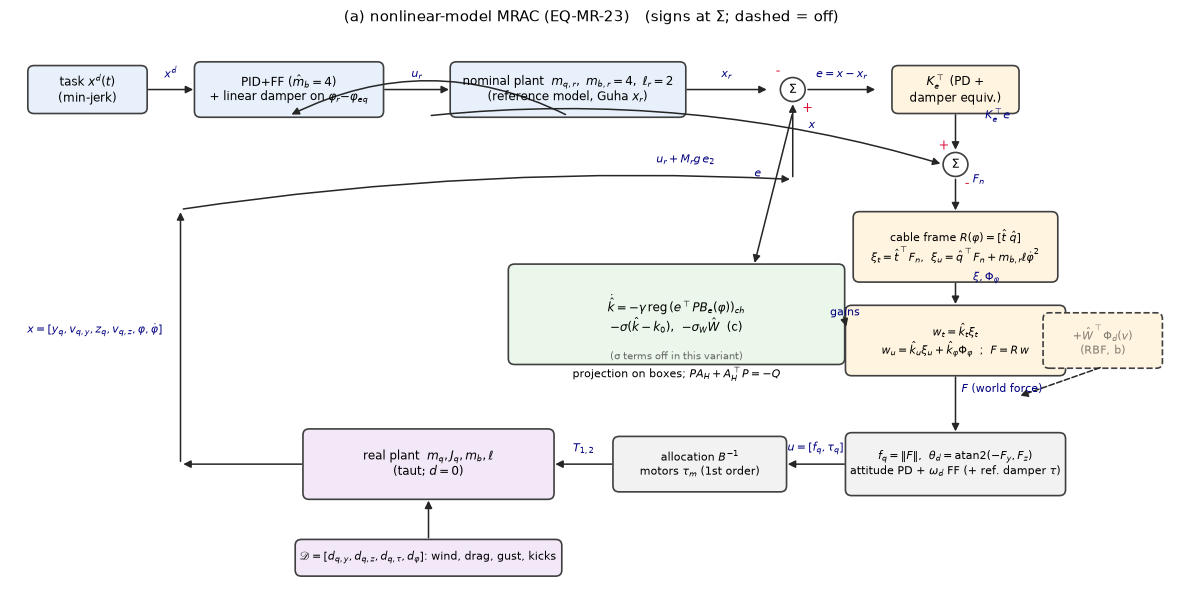

In [2]:
blockdiag.draw_vanilla_extensions("a"); plt.show()

## 3. The plant, derived step by step ($d = 0$)

> **Where this comes from.**
> - **Source:** MQP §6.15.1 ("Exact taut model at $d=0$"). Its two projections reproduce residual.tex eqs. (T_hybrid) and (phi_ddot_nl). The same model with an attachment offset is derived in NB05; here it is restricted to $d=0$.
> - **Prerequisites:** NB05 (Newton-Euler for the vehicle and the payload, the tension and swing projections); NB10 Section 2.1 (the same model linearized at hover).
> - **Assumptions:**
>   1. The rope is taut ($T^\varphi\ge 0$), massless and inextensible, with length $\ell$.
>   2. The payload is a point mass attached at the vehicle centre of mass ($d=0$), so the vehicle attitude does not enter.
>   3. The world force $F$ is the input (ideal inner loop).
>   4. No disturbances in this derivation.

**Step 0: geometry.** With $\hat q=[-\sin\varphi,-\cos\varphi]^\top$ and $\hat t=[\cos\varphi,-\sin\varphi]^\top$ we have $\hat q^\top\hat t=0$, $\hat q^\top\hat q=\hat t^\top\hat t=1$, $\hat q_z=-\cos\varphi$, $\hat t_z=-\sin\varphi$, and the derivatives $\partial\hat q/\partial\varphi=[-\cos\varphi,\sin\varphi]^\top=-\hat t$ and $\partial\hat t/\partial\varphi=[-\sin\varphi,-\cos\varphi]^\top=\hat q$.

**Step 1: Newton for both bodies.** The tension $T^\varphi\ge 0$ pulls the vehicle toward the load (along $\hat q$) and the load toward the vehicle:
$$m_q\ddot r_q = F - m_q g e_2 + T^\varphi\hat q,\qquad m_b\ddot r_b = -T^\varphi\hat q - m_b g e_2,\qquad r_b = r_q + \ell\hat q .$$

**Step 2: the constraint.** Differentiate $r_b = r_q + \ell\hat q(\varphi)$ twice; the rope length is fixed. First $\dot r_b=\dot r_q+\ell\dot\varphi\,\partial\hat q/\partial\varphi=\dot r_q-\ell\dot\varphi\hat t$. Again, with Step 0, $\ddot r_b=\ddot r_q-\ell\ddot\varphi\,\hat t-\ell\dot\varphi^2\hat q$. With $\hat q^\top \partial\hat q/\partial\varphi = 0$, the radial part of the load acceleration is $\hat q^\top\ddot r_b = \hat q^\top\ddot r_q - \ell\dot\varphi^2$ (the centripetal term), and the tangential part is $\hat t^\top\ddot r_b=\hat t^\top\ddot r_q-\ell\ddot\varphi$.

**Step 3: eliminate the tension.** Project the load equation on $\hat q$ (use $\hat q^\top\hat q=1$ and $\hat q^\top e_2=\hat q_z$): $m_b(\hat q^\top\ddot r_q-\ell\dot\varphi^2)=-T^\varphi-m_bg\hat q_z$. Solving for $T^\varphi$,
$$T^\varphi = m_b\big(\ell\dot\varphi^2 - g\hat q_z - \hat q^\top\ddot r_q\big) = m_b\big(g\cos\varphi + \hat u^\top\ddot r_q + \ell\dot\varphi^2\big),$$
which is exactly residual.tex eq. (T_hybrid) (with $\hat u=-\hat q$). The tangential projection ($\hat t^\top\hat q=0$, $\hat t^\top e_2=\hat t_z=-\sin\varphi$) gives $m_b(\hat t^\top\ddot r_q-\ell\ddot\varphi)=m_bg\sin\varphi$, which is the swing equation, residual.tex eq. (phi_ddot_nl):
$$\ell\ddot\varphi = -g\sin\varphi + \hat t^\top\ddot r_q .$$

**Step 4: substitute back.** Insert $T^\varphi$ into the vehicle equation. With the projectors $P_u = \hat q\hat q^\top$ (radial) and $P_t = \hat t\hat t^\top = I - P_u$ (tangential):
$$\underbrace{(m_q I + m_b P_u)}_{\tilde M(\varphi)}\ddot r_q = F - m_q g e_2 + m_b(\ell\dot\varphi^2 - g\hat q_z)\hat q .$$

$\tilde M = m_q P_t + M P_u$ is the **effective mass**:
- radially, the vehicle drags the whole payload, so the mass is $M$;
- tangentially, the payload swings freely, so the mass is $m_q$.

Its inverse is $\tilde M^{-1} = P_t/m_q + P_u/M$, because the projectors are orthogonal. Gravity collapses to $-g e_2$ in both channels. Write it out: $\tilde M^{-1}(-m_qge_2)=-gP_te_2-\frac{m_q}{M}gP_ue_2$, and, since $\hat q_z\hat q=P_ue_2$, $\tilde M^{-1}(-m_bg\hat q_z\hat q)=-\frac{m_b}{M}gP_ue_2$. Adding, with $\frac{m_q+m_b}{M}=1$ and $P_t+P_u=I$, gives $-gP_te_2-gP_ue_2=-ge_2$. The centripetal term lies along $\hat q$, so $\tilde M^{-1}$ divides it by $M$. Result:
$$\boxed{\ddot r_q = \tilde M^{-1}F - g e_2 + \frac{m_b}{M}\ell\dot\varphi^2\,\hat q}$$

This is a Lagrangian elimination in generalized coordinates (not a Hamiltonian form). Below, the closed form is checked against the simulator.

**Intuition.** Seen from the vehicle, the payload is a mass that is heavy along the cable (the vehicle must drag it) and invisible across it (the load swings freely), plus a centripetal pull toward the load when it swings fast. That is exactly what the effective mass $\tilde M$ and the last term encode.

In [3]:
import dataclasses, math
from experiments.mrac.baselines import canonical_offline_params
from experiments.mrac.quad_load_pend import PayloadParams, QuadLoadPend
from experiments.mrac.vanilla_nl_mrac import cable_frame_accel
canon = canonical_offline_params(); rng = np.random.default_rng(0); worst = 0.0
for _ in range(10):
    mq, mb, l = 9.6 * rng.uniform(.8, 1.2), rng.uniform(2, 6), rng.uniform(1.5, 2.5)
    plant = QuadLoadPend(dataclasses.replace(canon.quad, m=mq), PayloadParams(mb, l, 0.0))
    st = canon.with_condition(m_L=mb, cable_length=l).hover_state(theta=rng.uniform(-.3, .3), phi=rng.uniform(-.5, .5), phi_dot=rng.uniform(-1, 1))
    f, _ = plant.wrench(st.quad.c_L, st.quad.c_R)
    F = f * np.array([-math.sin(st.quad.theta), math.cos(st.quad.theta)])
    worst = max(worst, np.abs(cable_frame_accel(F, st.phi, st.phi_dot, m_q=mq, m_b=mb, l=l, g=9.81) - np.array(plant.accelerations(st).p_ddot)).max())
print(f"closed form vs simulator, 10 random taut states: max |difference| = {worst:.1e} m/s^2")

closed form vs simulator, 10 random taut states: max |difference| = 2.2e-15 m/s^2


## 4. Why the cable frame: one scalar effectiveness per channel

> **Where this comes from.**
> - **Source:** MQP §6.15.2 ("Cable-frame channels: one positive scalar effectiveness per channel"). The structure is Guha and Annaswamy's scalar effectiveness $\lambda$ (arXiv 2011.10562, eqs. 4 and 7): the plant input is $\lambda B_ru$ with an unknown positive scalar $\lambda$ of known sign.
> - **Prerequisites:** NB04 (Guha's scalar-$\lambda$ class); NB10 Section 2.2 (where the diagonal $\Lambda$ came from); Section 3 above.
> - **Assumptions:** (1) the rotation $R(\varphi)$ is known, because $\varphi$ is measured; (2) matched cable length, $\ell=\ell_r$; (3) $d=0$.

Write the world force in the cable frame, $F = R(\varphi)w$ with $R = [\hat t\ \hat q]$. The rotation is known, because $\varphi$ is measured. Then
$$\hat t^\top\ddot r_q = \frac{w_t}{m_q} - g\hat t_z,\qquad \hat q^\top\ddot r_q = \frac{w_u}{M} - g\hat q_z + \frac{m_b}{M}\ell\dot\varphi^2 .$$
To see this, note that $R^\top R=I$ gives $\hat t^\top F=w_t$ and $\hat q^\top F=w_u$. Apply $\hat t^\top$ and $\hat q^\top$ to the boxed result of Section 3: $\hat t^\top P_t=\hat t^\top$ and $\hat t^\top P_u=0$, so $\hat t^\top\tilde M^{-1}=\hat t^\top/m_q$; likewise $\hat q^\top\tilde M^{-1}=\hat q^\top/M$. Gravity gives $-g\hat t_z$ and $-g\hat q_z$, and $\hat t^\top\hat q=0$ removes the centripetal term from the $t$ channel.

Each channel has **one positive scalar effectiveness**, unknown in value but known in sign. This is the structure of Guha's $\lambda$:
$$\lambda_t = m_{q,r}/m_q,\qquad \lambda_u = M_r/M .$$

**Why the cable frame?** A single world-frame scalar $\lambda$ would need $m_b/m_q = m_{b,r}/m_{q,r}$, i.e. proportional masses (finding N4 of the independent Codex design review). Indeed, $\tilde M^{-1}=\lambda\tilde M_r^{-1}$ requires $1/m_q=\lambda/m_{q,r}$ and $1/M=\lambda/M_r$; eliminating $\lambda$ gives $m_q/m_{q,r}=M/M_r$, that is $1+m_b/m_q=1+m_{b,r}/m_{q,r}$. The cable frame removes that condition.

**Scope.** The two channels share one state through $B_e(\varphi)$. So this is a **local two-input extension using Guha's scalar-effectiveness and adaptive-law pattern channelwise**, proved in MQP §6.15. Guha's theorem itself is not imported.

**Intuition.** Along the cable the vehicle is "heavy" ($M$), across it the vehicle is "light" ($m_q$), and each direction has its own unknown mass ratio. Giving each direction its own adaptive scalar matches the physics. A single gain in world axes would force the unknown ratios of the two directions to be equal.

## 5. Law, ideal gains and the nominal identity

> **Where this comes from.**
> - **Source:** MQP §6.15.3 ("Reference, error and the nominal force") and §6.15.4 ("Law", EQ-MR-23).
> - **Prerequisites:** NB10 Sections 3 and 4 (reference, error feedback $K_e$, the law of the vanilla case); Sections 3 and 4 above.
> - **Assumptions:** (1) matched cable length $\ell=\ell_r$ and $d=0$; (2) the reference is the nominal vehicle with the nominal 4 kg / 2 m payload, flown by PID+FF plus the linear damper; (3) the regressors use the measured $\varphi$, $\dot\varphi$ and the reference signals.

**Nominal command.** The vanilla error path (NB10) gives the nominal world force: the PD+FF+damper action on $e = x - x_r$,
$$F_n = u_r + M_r g e_2 - K_e^\top e .$$
Here $u_r$ is the reference policy's gravity-offset command (called $\nu_r$ in NB10), so $F_n=\xi+M_rg\,e_2$, with $\xi=u_r-K_e^\top e$ the corrected command of NB10.

**Target acceleration.** The nominal model's acceleration at the plant's own angle is the boxed formula of Section 3 with the reference parameters and the force $F_n$:
$$a_d=\tilde M_r^{-1}F_n-ge_2+\frac{m_{b,r}}{M_r}\ell\dot\varphi^2\hat q .$$
The law is built so that the real plant accelerates as $\ddot r_q=a_d$.

**Regressors.**
$$\xi_t = \hat t^\top F_n,\qquad \xi_u = \hat q^\top F_n + m_{b,r}\ell\dot\varphi^2,\qquad \Phi_\varphi = -\ell\dot\varphi^2 .$$

**Law.**
$$w_t = \hat k_t\,\xi_t,\qquad w_u = \hat k_u\,\xi_u + \hat k_\varphi\,\Phi_\varphi,\qquad F = R(\varphi)\,w .$$

**Ideal gains.** $k_t^* = m_q/m_{q,r} = 1/\lambda_t$, $k_u^* = M/M_r = 1/\lambda_u$, $k_\varphi^* = m_b$.

**Check that the ideals reproduce $a_d$.**
- $t$ channel: $\hat t^\top\ddot r_q=\dfrac{w_t^*}{m_q}-g\hat t_z=\dfrac{(m_q/m_{q,r})\,\hat t^\top F_n}{m_q}-g\hat t_z=\dfrac{\hat t^\top F_n}{m_{q,r}}-g\hat t_z=\hat t^\top a_d$, because $\hat t^\top\tilde M_r^{-1}=\hat t^\top/m_{q,r}$ and $\hat t^\top\hat q=0$.
- $u$ channel: $w_u^*=\dfrac M{M_r}\big(\hat q^\top F_n+m_{b,r}\ell\dot\varphi^2\big)-m_b\ell\dot\varphi^2$, so
$$\frac{w_u^*}{M}+\frac{m_b}{M}\ell\dot\varphi^2=\frac{\hat q^\top F_n+m_{b,r}\ell\dot\varphi^2}{M_r}=\frac{\hat q^\top F_n}{M_r}+\frac{m_{b,r}}{M_r}\ell\dot\varphi^2 ,$$
the two $m_b\ell\dot\varphi^2/M$ terms cancelling. Subtracting $g\hat q_z$ gives $\hat q^\top a_d$.

**Which terms cancel.** With the ideals, $w_u^*/M + (m_b/M)\ell\dot\varphi^2 = \hat q^\top F_n/M_r + (m_{b,r}/M_r)\ell\dot\varphi^2$. The real payload's centripetal pull is removed and the nominal one restored, so the plant accelerates exactly as the nominal model would under $F_n$.

**Nominal identity.** At the nominal gains $(1, 1, m_{b,r})$, $w = R^\top F_n$, so $F = F_n$. A nominal plant therefore reproduces the reference exactly (checked: $\|e\| < 10^{-10}$). Indeed $w_t=\xi_t=\hat t^\top F_n$ and $w_u=\xi_u+m_{b,r}\Phi_\varphi=\hat q^\top F_n$, and $RR^\top=I$.

**Intuition.** The law reads the nominal command, resolves it along and across the cable, and rescales each part by an unknown mass ratio so that the real vehicle accelerates like the nominal one. A third term removes the real payload's centripetal pull and the regressor $\xi_u$ puts the nominal one back.

## 6. Error equation and Lyapunov function, line by line

> **Where this comes from.**
> - **Source:** MQP §6.15.5 ("Error equation and Lyapunov function", the pattern of Guha's Thm. 3: storage $\lambda\tilde k^2/\gamma$ per channel).
> - **Prerequisites:** NB10 Sections 3 and 4 (the error $e$, $A_H$, the Lyapunov equation, the cancellation of the cross term); Sections 3 to 5 of this notebook.
> - **Assumptions:**
>   1. $d=0$ and $\ell=\ell_r$; $m_q$ and $m_b$ are unknown constants; the ideal gains $k^*$ are constant.
>   2. The force $F$ is realized exactly: continuous time, no projection, no saturation, ideal inner loop.
>   3. $P=P^\top>0$ solves $PA_H+A_H^\top P=-Q$ with $Q=Q^\top>0$ and $A_H=A_r-B_rK_e^\top$ from NB10.
>   4. $\gamma_t,\gamma_u,\gamma_\varphi>0$.

**0. Deviation of the real plant from the nominal model.** Write $w=w^*+\tilde w$ with $\tilde w=(\tilde k_t\xi_t,\ \tilde k_u\xi_u+\tilde k_\varphi\Phi_\varphi)$ and $\tilde k=\hat k-k^*$. The cable-frame equations of Section 4 are affine in $w$ and the ideal $w^*$ gives $\ddot r_q=a_d$ (Section 5), so
$$\ddot r_q=a_d+\frac{\tilde w_t}{m_q}\hat t+\frac{\tilde w_u}{M}\hat q=a_d+R(\varphi)D\tilde w,\qquad D=\mathrm{diag}(1/m_q,\,1/M).$$
In the swing equation $\ell\ddot\varphi=-g\sin\varphi+\hat t^\top\ddot r_q$ only the $t$ part enters, because $\hat t^\top\hat q=0$: the extra swing acceleration is $\tilde w_t/(m_q\ell)$. In the state order $(y_q,v_{q,y},z_q,v_{q,z},\varphi,\dot\varphi)$ this is
$$\dot x=f_{\rm nom}(x,F_n)+B_e(\varphi)D\tilde w,\qquad B_e(\varphi)=\begin{bmatrix}0&0\\ \hat t_y&\hat q_y\\ 0&0\\ \hat t_z&\hat q_z\\ 0&0\\ 1/\ell&0\end{bmatrix}\in\mathbb R^{6\times2},$$
where $f_{\rm nom}(x,F)$ is the nominal model (reference parameters, Section 3 equations) evaluated at the plant state. The $+1/\ell$ in the $\dot\varphi$ row is in residual.tex $\varphi$ ($-1/\ell$ in the code's $\varphi$). The reference runs on its own force $F_r=u_r+M_rge_2$: $\dot x_r=f_{\rm nom}(x_r,F_r)$.

**1. Error dynamics.** With ideal gains the plant follows the nominal model evaluated at the plant state. Subtract the reference: $\dot e=f_{\rm nom}(x,F_n)-f_{\rm nom}(x_r,F_r)+B_eD\tilde w$. At hover $f_{\rm nom}(x,F)\approx A_rx+B_r(F-M_rge_2)$, and $F_n-F_r=-K_e^\top e$, so the difference is $A_re-B_rK_e^\top e=A_He$ plus a remainder $N$ that collects everything beyond this linear expression. Let $\tilde w = (\tilde k_t\xi_t,\ \tilde k_u\xi_u + \tilde k_\varphi\Phi_\varphi)$ and $D = \mathrm{diag}(1/m_q, 1/M)$. Then
$$\dot e = A_H e + N(x, x_r) + B_e(\varphi)\,D\,\tilde w,$$
where:
- $A_H = A_r - B_r K_e^\top$ is Hurwitz (NB10 §3);
- $N$ is the known kinematic remainder of the linearization. It is defined by $N=f_{\rm nom}(x,F_n)-f_{\rm nom}(x_r,F_r)-A_He$: second order in $e$ plus the variation of the Jacobian along the trajectory. It can be computed from $x,x_r$, but nothing in this notebook bounds it;
- $B_e(\varphi)$ places a unit channel acceleration in the error rows: velocity along $\hat t$ or $\hat q$, and $\pm 1/\ell$ in the $\dot\varphi$ row for the $t$ channel.

**2. Storage.** As in Guha's $\lambda\tilde k^2/\gamma$, with the unknown positive $1/m_q$ and $1/M$ in the role of $\lambda$:
$$V = e^\top Pe + \frac{\tilde k_t^2}{m_q\gamma_t} + \frac{\tilde k_u^2}{M\gamma_u} + \frac{\tilde k_\varphi^2}{M\gamma_\varphi},\qquad PA_H + A_H^\top P = -Q .$$
$V>0$ unless $e=0$ and $\tilde k=0$.

**3. Differentiate.** $P$ is symmetric and the ideal gains are constant ($\dot{\tilde k}=\dot{\hat k}$):
$$\dot V=e^\top(PA_H+A_H^\top P)e+2e^\top PN+2e^\top PB_eD\tilde w+\frac{2\tilde k_t\dot{\hat k}_t}{m_q\gamma_t}+\frac{2\tilde k_u\dot{\hat k}_u}{M\gamma_u}+\frac{2\tilde k_\varphi\dot{\hat k}_\varphi}{M\gamma_\varphi}.$$
The first term is $-e^\top Qe$. Since $D$ is diagonal and $e^\top PB_e\in\mathbb R^{1\times2}$ (subscripts $t,u$ pick its two entries), the cross term is
$$2e^\top PB_eD\tilde w=2(e^\top PB_e)_t\frac{\tilde k_t\xi_t}{m_q}+2(e^\top PB_e)_u\frac{\tilde k_u\xi_u+\tilde k_\varphi\Phi_\varphi}{M}.$$
Assembled:
$$\dot V = -e^\top Qe + 2e^\top PN + 2(e^\top PB_e)_t\frac{\tilde k_t\xi_t}{m_q} + 2(e^\top PB_e)_u\frac{\tilde k_u\xi_u + \tilde k_\varphi\Phi_\varphi}{M} + \frac{2\tilde k_t\dot{\hat k}_t}{m_q\gamma_t} + \frac{2\tilde k_u\dot{\hat k}_u}{M\gamma_u} + \frac{2\tilde k_\varphi\dot{\hat k}_\varphi}{M\gamma_\varphi}.$$

**4. Choose the updates** so that each cross term cancels its storage term. The unknown $1/m_q$ and $1/M$ factor out, so they are never needed:
$$\dot{\hat k}_t = -\gamma_t\xi_t(e^\top PB_e)_t,\qquad \dot{\hat k}_u = -\gamma_u\xi_u(e^\top PB_e)_u,\qquad \dot{\hat k}_\varphi = -\gamma_\varphi\Phi_\varphi(e^\top PB_e)_u .$$
Substituting: $\frac{2\tilde k_t\dot{\hat k}_t}{m_q\gamma_t}=-\frac{2\tilde k_t\xi_t(e^\top PB_e)_t}{m_q}$ cancels the $t$ cross term; $\frac{2\tilde k_u\dot{\hat k}_u}{M\gamma_u}=-\frac{2\tilde k_u\xi_u(e^\top PB_e)_u}{M}$ and $\frac{2\tilde k_\varphi\dot{\hat k}_\varphi}{M\gamma_\varphi}=-\frac{2\tilde k_\varphi\Phi_\varphi(e^\top PB_e)_u}{M}$ cancel the two pieces of the $u$ cross term.

**Intuition.** This is the same cancellation as in NB10, now channel by channel in the cable frame: each unknown mass ratio enters through one channel, so one adaptive scalar per channel (plus the centripetal gain) removes it. What is left, $2e^\top PN$, is the price of using a nonlinear model with a linear error equation: nothing here controls its size.

**5. Result.** $\dot V = -e^\top Qe + 2e^\top PN(x, x_r)$.
- **Proved:** this identity, i.e. the exact cancellation of the parametric uncertainty.
- **Not proved:** convergence. That needs a bound on $N$ near the trajectory, an invariant region inside the taut domain, and regularity (MQP §6.15.5).
- **Not part of the calculation:** the sampled loop, the projection, the motor lag and the inner attitude loop. They are checked numerically below.

## 7. Before running: the sampled loop is checked locally (per-stage preflight)

The proof is continuous-time; the real tick is sampled at 50 Hz with motor lag. The runner therefore checks every condition before any episode, using a finite-difference Jacobian of one real tick at hover with ideal gains:
- The unexcited gain directions ($\hat k_t$ because $\xi_t = 0$ at hover, $\hat k_\varphi$ because $\dot\varphi = 0$, and the RBF directions orthogonal to $\Phi_d(0)$) are removed structurally. They are checked invariant and with eigenvalue exactly 1 (the one-tick map leaves them unchanged).
- The remaining growth rate must be negative.
- $\gamma_u = 0.03$ was fixed by this screen before any protocol data (protocol 08, amendment AM1). The rule: take the largest value in $\{0.0562,0.03,0.02,0.015,0.01\}$ for which every protocol hover plant ($m_b$ from 2 to 6 kg, $m_q$ from $0.7\times$ to $1.3\times$) decays at no more than $-0.05$ /s. The result is 0.03, with worst case $-0.25$ /s; the direct mapping $1000/(M_rg)^2=0.056$ grew at 2 kg (MQP §6.15.6, "Gains, fixed before the protocol-08 data").

In [4]:
ST = latest("a")
print("stage folder:", ST)
rec = json.loads((ST / "receipt.json").read_text())
if "composite_of" in rec:  # completion parts combined (protocol 08 AM3)
    print("composite of:", [(p["folder"], p["status"], p.get("n_results")) for p in rec["composite_of"]])
    rec = rec["composite_of"][0]
print("status", rec["status"], "| wall", round(rec.get("wall_s", 0)), "s | thesis", rec["thesis_commit"][:7], "| dirty", rec["dirty_paths"])
display(pd.DataFrame(rec["preflight"]).T.round(4))

stage folder: results\mrac_ext_a_20261125T121348
status completed | wall 6549 s | thesis 57a3372 | dirty []


,rate_per_s,invariance,drift
veh_nominal,-0.3533,0.0,0.0000
veh_m_q-20%,-0.2981,0.0,0.0000
veh_m_q-10%,-0.3411,0.0,0.0000
veh_m_q+10%,-0.3480,0.0,0.0000
veh_m_q+20%,-0.3428,0.0,0.0000
veh_J-30%,-0.3533,0.0,0.0000
veh_J-15%,-0.3533,0.0,0.0000
veh_J+15%,-0.3533,0.0,0.0000
veh_J+30%,-0.3533,0.0,0.0000
veh_a_p-10%,-0.3533,0.0,0.0000


## 8. Results: grid over vehicle and payload mismatch (interactive)

- **Rows:** conditions. These are the 15 vehicle-mismatch cases (mass, inertia, arm, motor asymmetry) at 4 kg / 2 m, plus payload mass and rope length.
- **Columns:** arms. This variant's ONLINE (adaptation on) and FROZEN (the same design with the estimates held fixed, no updates), TUNED' vanilla (`v0_online`, called V0 in protocol 08: the vanilla law of NB10 with the gains chosen under tuning protocol 06), and the PID+FF and softer-damper baselines.
- **Controls:** tick or untick arms, and choose the metric, scenario, disturbance and set.

In [5]:
folders = [latest(s) for s in ['a']]
S = ext_panels.load_summaries([f for f in folders if f is not None])
ext_panels.grid_panel(S)

## 9. Episodes: (i) temporal, (ii) gain convergence, (iii) Lyapunov variables (interactive)

Choose a condition, scenario and disturbance, then toggle arms and plot groups.
- The `long` set holds the 600 s transfers, where the gains have time to converge.
- Kicks are at 30 s and 60 s; the red dotted lines mark them.

In [6]:
ext_panels.episode_panel(S)

## 10. Which statement improves which (protocol 08 §6 rule)

"X improves on Y in a disturbance class" when X has the lower task error in at least 75 % of the class's comparable paired cells, **and** the swing gate G3' is *True* for X there. G3' is protocol 06's swing gate: the swing RMS over 10 to 30 s must not exceed $\max(B_S,\,0.005\ \mathrm{rad})$, with $B_S$ the softer baseline's swing plus half of any excess of PID+FF over it. Unknown G3' never passes.
- **Both directions** are scored with each arm's own G3'.
- **A failed episode** makes its cell non-comparable; it never becomes the other arm's win.
- **Scored sets:** only the grid and disturbance sets. The 600 s holds and the `d = 0.3795` runs are readouts.
- **Nature of the test:** descriptive and deterministic (one run per cell, three OU seeds).
- **PE Gramian:** NOT MEASURED in this protocol run, so **no parameter-convergence claim** is made (finding EXT-05 of the independent Codex review of the extensions report).

In [7]:
from mrac_lab import ext_analysis
an_folders = [f for f in folders if f is not None]
res = ext_analysis.compare(ext_analysis.load(an_folders))
rows = [dict(comparison=p, disturbance=d, comparable=v["comparable"], X_scores=v["x_scores"], X_improves=v["x_improves"],
             Y_scores=v["y_scores"], Y_improves=v["y_improves"], G3_unknown_X=v["g3_unknown_x"],
             failed_X=v["failed_x"], failed_Y=v["failed_y"], median_X=v["median_x"], median_Y=v["median_y"])
        for p, r in res.items() for d, v in r.items()]
display(pd.DataFrame(rows).round(5))
display(ext_analysis.kick_table(ext_analysis.load(an_folders)).round(4))

,comparison,disturbance,comparable,X_scores,X_improves,Y_scores,Y_improves,G3_unknown_X,failed_X,failed_Y,median_X,median_Y
0,a_online vs v0_online,D0 none,42,36,True,6,False,0,0,0,0.00000,0.00000
1,a_online vs v0_online,D1 constant,12,0,False,12,True,0,0,0,0.14238,0.00002
2,a_online vs v0_online,D3 drag,12,0,False,12,True,0,0,0,0.19807,0.00002
3,a_online vs v0_online,D4 gust,12,0,False,12,True,0,0,0,0.18848,0.11899
4,a_online vs v0_online,D2 OU,36,0,False,36,True,0,0,0,0.13281,0.04956
5,a_online vs v0_online,D5 payload kick,12,4,False,8,False,0,0,0,0.05289,0.05284
6,a_online vs v0_online,D6 vehicle kick,12,0,False,12,True,0,0,0,0.06314,0.05431
7,a_online vs a_frozen,D0 none,42,20,False,22,False,0,0,0,0.00000,0.00000
8,a_online vs a_frozen,D1 constant,12,12,True,0,False,0,0,0,0.14238,0.40896
9,a_online vs a_frozen,D3 drag,12,12,True,0,False,0,0,0,0.19807,0.44100


kick0_swing_rms_5s  kick0_task_max_5s  kick0_settle_s  \
dist         arm                                                                
payload_kick a_frozen               0.0585             0.5143            4.37   
             a_online               0.0579             0.3779            4.25   
             pidff                  0.0904             0.1491            7.01   
             softer                 0.0753             0.2832            5.84   
             v0_online              0.0627             0.3409            8.54   
vehicle_kick a_frozen               0.0299             0.5231            4.98   
             a_online               0.0299             0.3636            4.90   
             pidff                  0.0480             0.2276            6.13   
             softer                 0.0382             0.2469            4.93   
             v0_online              0.0407             0.2774            8.87   

                        kick1_settle_s  
dist         arm                        
payload_kick a_frozen             4.37  
             a_online             4.27  
             pidff                7.01  
             softer               5.84  
             v0_online            8.52  
vehicle_kick a_frozen             4.98  
             a_online             4.90  
             pidff                6.13  
             softer               4.93  
             v0_online            8.82

## 11. Live: tune the gains yourself (one short episode per button press)

In [8]:
ext_panels.live_panel("a")

## 12. Claim limits

- **Exact:** the cancellation of the parametric uncertainty in the derivative identity, for the continuous, unprojected force-input model at $d = 0$.
- **Not proved:** local convergence (premises listed in MQP §6.15.5, "Error equation and Lyapunov function").
- **Numerical evidence only:** the sampled loop, which is local and finite-horizon, on a single machine (PROXY).
- **Not claimed:**
  - parameter convergence without excitation ($\hat k_\varphi$ needs swing, $\hat k_t$ needs lateral force);
  - results for $d \ne 0$ (the `robust` set is a readout only);
  - Pymunk, hardware or multi-vehicle results.
- **Next:** with Javier's approval, replace the linear damper inside the reference policy by the frozen residual policy.